In [7]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Load Hardware Data

# Device selection

In [8]:
from cobos.tokens import ibm_token, group_instance, group_instance2
from qiskit_ibm_runtime import QiskitRuntimeService

channel = "ibm_quantum"
# device = "ibm_fez"
# device = "ibm_sherbrooke"
# device = "ibm_torino"
# device = "ibm_marrakesh"
# device = "ibm_aachen"
device = "ibm_kingston"

service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)
backend = service.backend(device)

# Auxiliary lattice plot

60 possible layouts


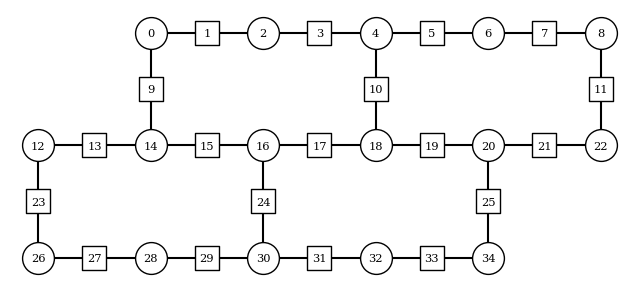

In [9]:
from z2hex.geometry import HeavyHexLattice

plaquette_width = 2
plaquette_height = 2

lattice = HeavyHexLattice(plaquette_width, plaquette_height)
nlayouts = len(lattice.get_all_layouts(backend))
print(f"{nlayouts} possible layouts")
lattice.plot_lattice(number_qubits=True)

# Simulation settings

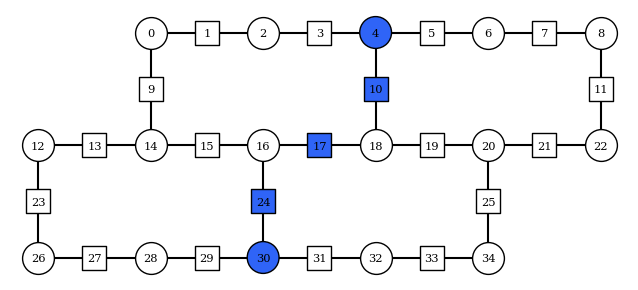

In [10]:
from z2hex.gdd import zero_mean
from utils.hexec import create_estimator_options
from utils.execrecord import ExecutionRecord
from utils.hexec import ExecDB
from functools import partial

lattice_dims = (plaquette_width, plaquette_height)
J = 5
h = 2
lamb = 1

x_basis = False

fractional_gates = False

# string = [27, 26, 34, 43, 52, 60, 71, 78]
# string = [21, 33, 41, 52, 62, 72, 83, 91, 103]
# string = [0, 1, 3, 6, 11]
string = [4, 10, 17, 24, 30]

final_time = 2
dt = 0.1
steps = 40
desired_error = 1e-2

max_layers = 50
adjust_depth = True

shots = 75000
confidence = 0.7

odr = True
postselect_odr = True
flip_threshold = 3
all_or_first_layout_qubit = None
forbidden_qubits = []
max_layouts = 4
recovery = True
# g_func = None
# g_func = partial(counteract_rotation, ham_param=J)
# g_func = partial(constant, angle=np.pi)
# g_func = random
g_func = zero_mean

sampler_options = {
    "default_shots": shots,
    "execution": {
        "init_qubits": True,
        "meas_type": "classified"
    },
    "dynamical_decoupling": {
        "enable": True,
        "sequence_type": "XY4"
    },
    "twirling": {
        "enable_gates": True,
        "enable_measure": True,
        "num_randomizations": "auto",
        "shots_per_randomization": "auto"
    },
    "experimental": {
        "execution_path": "gen3-turbo"
    }
}

execution_database = "z2_hex_jobs_dec.json"
jobs_result_folder = execution_database.split(".")[0] + "/"
job_db = ExecDB(execution_database)

circ_folder_path = "Circuits/"

execution_record_path = "../../../../Executions_record.xlsx"
execrecord = ExecutionRecord(execution_record_path)

curated_data_folder_path = "Curated data/"

lattice.plot_highlighted_qubits(string, colors=["#2f64f7"]*len(string), number_qubits=True)

# Load jobs

In [11]:
from utils.postselection_multithreaded import load_postselected_jobs_obs
import pickle
import os

curated_data_filepath = os.path.join(curated_data_folder_path, f"z2hexquench_curated_data_{device}_px_{lattice_dims[0]}_py_{lattice_dims[1]}_maxt_{final_time}_dt_{dt}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else g_func}_shots_{shots}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}_ft_{flip_threshold}_pODR_{postselect_odr}_confidence_{confidence}.pkl")

with open(curated_data_filepath, "rb") as f:
    hardware_observables, hardware_observables_confidence, samples_dicts, postselected_samples_dicts, layouts = pickle.load(f)

# Load TN data

In [14]:
import numpy as np
import os

tn_dt = 0.01
tn_final_time = 16
tn_exp_order = 30
tn_bond_dimension = 128
tn_data_folderpath = "TN Data/"

tn_data_filepath = os.path.join(tn_data_folderpath, f"converted_data_BUG_g{h:.02f}_m{J:.02f}_ROWS2_COLS2_dt{tn_dt:.03f}_Tmax{tn_final_time:.02f}_exp_order{tn_exp_order}_M{tn_bond_dimension:05d}.txt")
tn_observables = np.loadtxt(tn_data_filepath)

# Plots

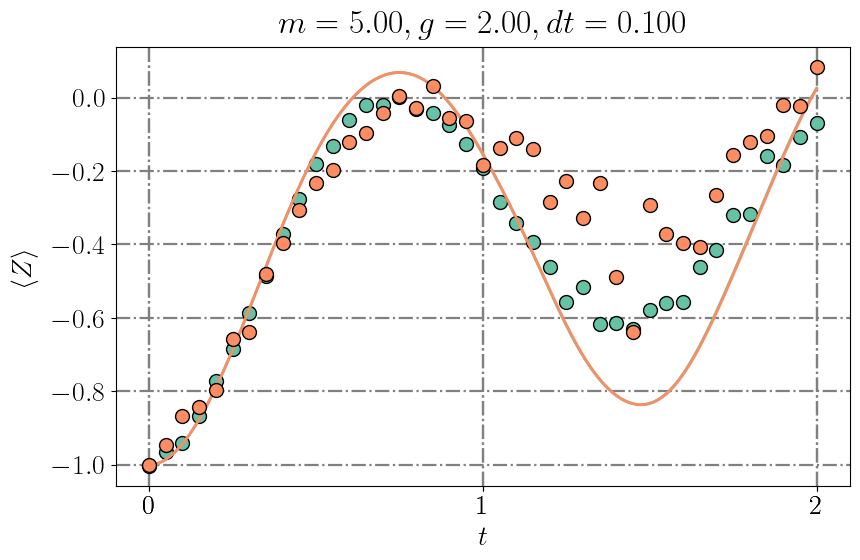

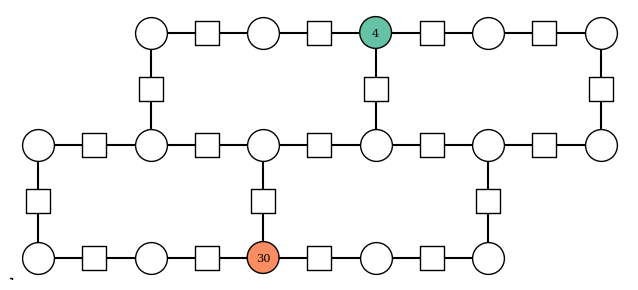

In [15]:
from utils.plotting import plot_individual_qubits_htn_comparison
import matplotlib.pyplot as plt

qubits = [4, 30]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.round(np.linspace(0, final_time, 6))
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"

plot_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = hardware_observables[0]
tn_observables_to_plot = tn_observables[:200, :]

plot_individual_qubits_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, qubits, x_ticks=x_ticks, x_label=x_label, title=title, y_label=y_label, y_lim=None, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(qubits), filepath=legend_filepath)

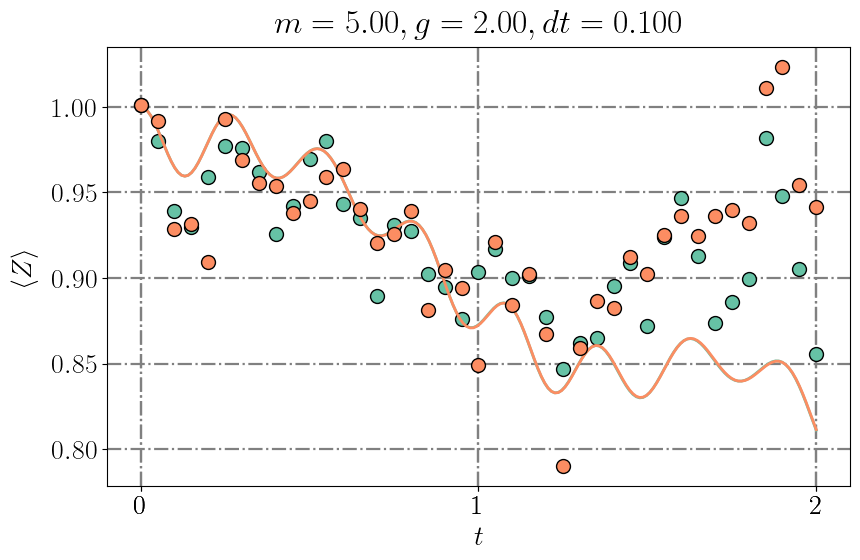

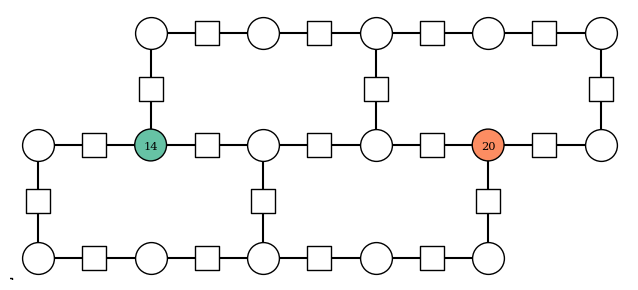

In [17]:
from utils.plotting import plot_individual_qubits_htn_comparison
import matplotlib.pyplot as plt

qubits = [14, 20]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.round(np.linspace(0, final_time, 6))
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"

plot_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = hardware_observables[0]
tn_observables_to_plot = tn_observables[:200, :]

plot_individual_qubits_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, qubits, x_ticks=x_ticks, x_label=x_label, title=title, y_label=y_label, y_lim=None, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(qubits), filepath=legend_filepath)

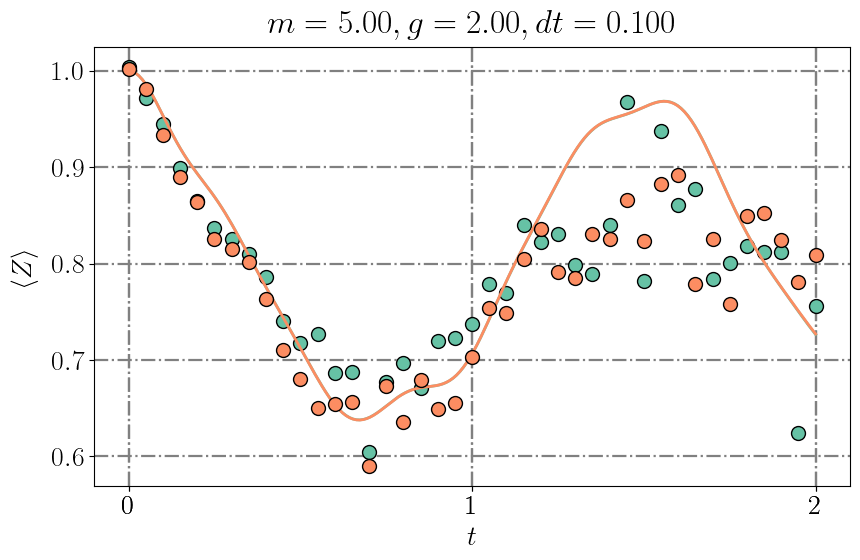

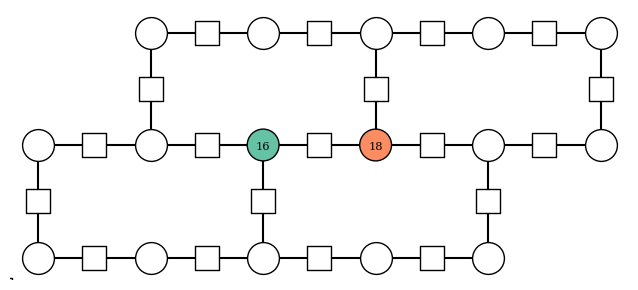

In [18]:
from utils.plotting import plot_individual_qubits_htn_comparison
import matplotlib.pyplot as plt

qubits = [16, 18]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.round(np.linspace(0, final_time, 6))
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"

plot_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = hardware_observables[0]
tn_observables_to_plot = tn_observables[:200, :]

plot_individual_qubits_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, qubits, x_ticks=x_ticks, x_label=x_label, title=title, y_label=y_label, y_lim=None, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(qubits), filepath=legend_filepath)

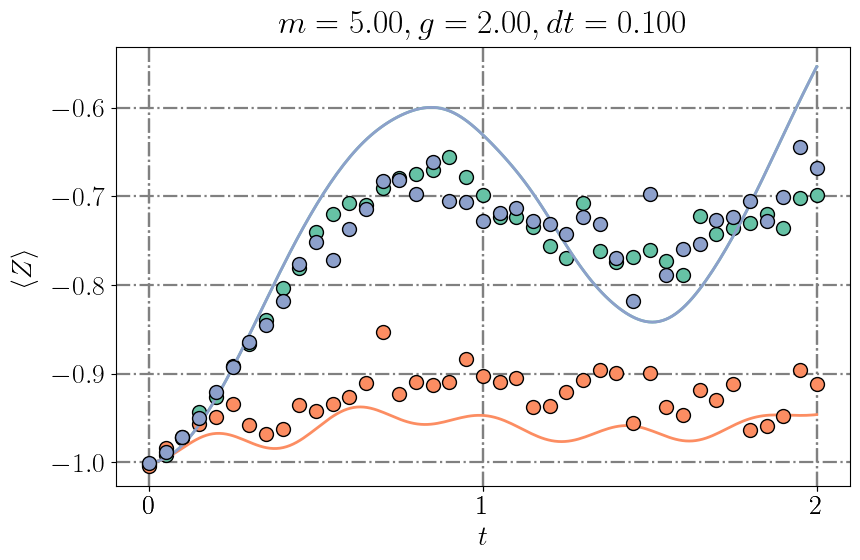

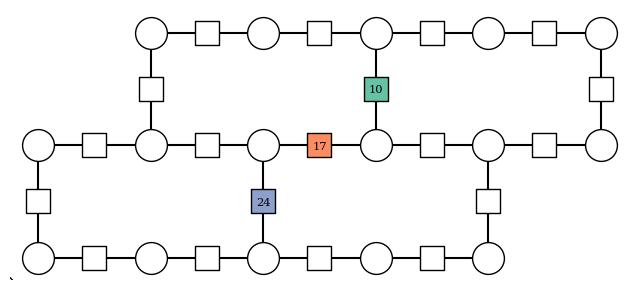

In [19]:
from utils.plotting import plot_individual_qubits_htn_comparison
import matplotlib.pyplot as plt

qubits = [10, 17, 24]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.round(np.linspace(0, final_time, 6))
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"

plot_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = hardware_observables[0]
tn_observables_to_plot = tn_observables[:200, :]

plot_individual_qubits_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, qubits, x_ticks=x_ticks, x_label=x_label, title=title, y_label=y_label, y_lim=None, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(qubits), filepath=legend_filepath)